**CH.SC.U4CSE24142 - SANTHOSH A - WEB SCRAPING**

In [ ]:
!pip install requests
!pip install beautifulsoup4
!pip install pandas
!pip install matplotlib

In [ ]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

In [ ]:
url = "https://realpython.github.io/fake-jobs/"

response = requests.get(url)

print(response.status_code)

200


In [ ]:
print(response.text[:500])

<!DOCTYPE html>
<html>
  <head>
    <meta charset="utf-8">
    <meta name="viewport" content="width=device-width, initial-scale=1">
    <title>Fake Python</title>
    <link rel="stylesheet" href="https://cdn.jsdelivr.net/npm/bulma@0.9.2/css/bulma.min.css">
  </head>
  <body>
  <section class="section">
    <div class="container mb-5">
      <h1 class="title is-1">
        Fake Python
      </h1>
      <p class="subtitle is-3">
        Fake Jobs for Your Web Scraping Journey
      </p>
    </div>


In [ ]:
soup = BeautifulSoup(response.text, "html.parser")

In [ ]:
# Find all job card elements
jobs = soup.find_all("div", class_="card-content")
# Count the number of jobs found
print(f"Number of jobs on this page: {len(jobs)}")

Number of jobs on this page: 100


In [ ]:
titles = []
companies = []
locations = []
dates = []

In [ ]:
for job in jobs:
    title = job.find("h2", class_="title").text.strip()
    company = job.find("h3", class_="company").text.strip()
    location = job.find("p", class_="location").text.strip()
    date = job.find("time")["datetime"]

    titles.append(title)
    companies.append(company)
    locations.append(location)
    dates.append(date)

In [ ]:
print(titles[:10])

['Senior Python Developer', 'Energy engineer', 'Legal executive', 'Fitness centre manager', 'Product manager', 'Medical technical officer', 'Physiological scientist', 'Textile designer', 'Television floor manager', 'Waste management officer']


In [ ]:
print(companies[:10])

['Payne, Roberts and Davis', 'Vasquez-Davidson', 'Jackson, Chambers and Levy', 'Savage-Bradley', 'Ramirez Inc', 'Rogers-Yates', 'Kramer-Klein', 'Meyers-Johnson', 'Hughes-Williams', 'Jones, Williams and Villa']


In [ ]:
print(locations[:10])

['Stewartbury, AA', 'Christopherville, AA', 'Port Ericaburgh, AA', 'East Seanview, AP', 'North Jamieview, AP', 'Davidville, AP', 'South Christopher, AE', 'Port Jonathan, AE', 'Osbornetown, AE', 'Scotttown, AP']


In [ ]:
data = {
    "Title": titles,
    "Company": companies,
    "Location": locations,
    "Date": dates
}

df = pd.DataFrame(data)

print(df.head())

                     Title                     Company              Location  \
0  Senior Python Developer    Payne, Roberts and Davis       Stewartbury, AA   
1          Energy engineer            Vasquez-Davidson  Christopherville, AA   
2          Legal executive  Jackson, Chambers and Levy   Port Ericaburgh, AA   
3   Fitness centre manager              Savage-Bradley     East Seanview, AP   
4          Product manager                 Ramirez Inc   North Jamieview, AP   

         Date  
0  2021-04-08  
1  2021-04-08  
2  2021-04-08  
3  2021-04-08  
4  2021-04-08  


In [ ]:
df.to_csv("fake_jobs.csv", index=False)

In [ ]:
df = pd.read_csv("fake_jobs.csv")

In [ ]:
print(df.head())

                     Title                     Company              Location  \
0  Senior Python Developer    Payne, Roberts and Davis       Stewartbury, AA   
1          Energy engineer            Vasquez-Davidson  Christopherville, AA   
2          Legal executive  Jackson, Chambers and Levy   Port Ericaburgh, AA   
3   Fitness centre manager              Savage-Bradley     East Seanview, AP   
4          Product manager                 Ramirez Inc   North Jamieview, AP   

         Date  
0  2021-04-08  
1  2021-04-08  
2  2021-04-08  
3  2021-04-08  
4  2021-04-08  


In [ ]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Title     100 non-null    str  
 1   Company   100 non-null    str  
 2   Location  100 non-null    str  
 3   Date      100 non-null    str  
dtypes: str(4)
memory usage: 9.3 KB
None


In [ ]:
print(df.describe())

                                  Title     Company         Location  \
count                               100         100              100   
unique                               92          99              100   
top     Python Programmer (Entry-Level)  Garcia PLC  Stewartbury, AA   
freq                                  3           2                1   

              Date  
count          100  
unique           1  
top     2021-04-08  
freq           100  


In [ ]:
print(df.isnull().sum())

Title       0
Company     0
Location    0
Date        0
dtype: int64


In [ ]:
df = df.dropna()

In [ ]:
print(df.duplicated().sum())

0


In [ ]:
df = df.drop_duplicates()

In [ ]:
df["Title"] = df["Title"].str.strip()
df["Title"] = df["Title"].str.lower()

In [ ]:
python_jobs = df[df["Title"].str.contains("python")]
print(f"Number of python related jobs: {len(python_jobs)}")

Number of python related jobs: 10


In [ ]:
df.sort_values("Date", ascending=False)

,Title,Company,Location,Date
0,senior python developer,"Payne, Roberts and Davis","Stewartbury, AA",2021-04-08
1,energy engineer,Vasquez-Davidson,"Christopherville, AA",2021-04-08
2,legal executive,"Jackson, Chambers and Levy","Port Ericaburgh, AA",2021-04-08
3,fitness centre manager,Savage-Bradley,"East Seanview, AP",2021-04-08
4,product manager,Ramirez Inc,"North Jamieview, AP",2021-04-08
...,...,...,...,...
95,museum/gallery exhibitions officer,"Nguyen, Yoder and Petty","Lake Abigail, AE",2021-04-08
96,"radiographer, diagnostic",Holder LLC,"Jacobshire, AP",2021-04-08
97,database administrator,Yates-Ferguson,"Port Susan, AE",2021-04-08
98,furniture designer,Ortega-Lawrence,"North Tiffany, AA",2021-04-08


In [ ]:
df.to_csv("fake_jobs_clean.csv", index=False)

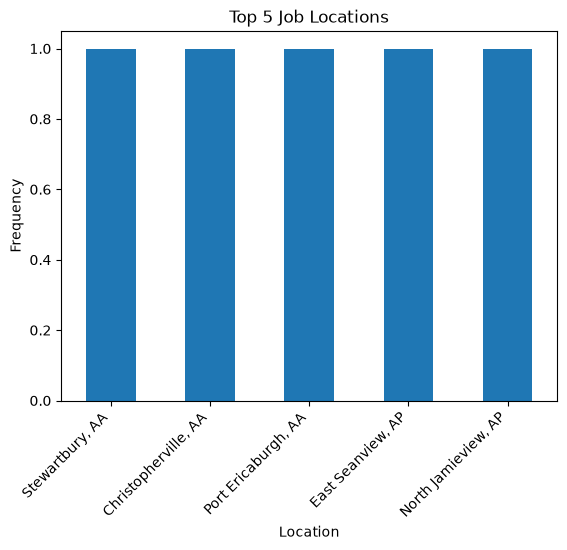

In [ ]:
import matplotlib.pyplot as plt

top_locations = df["Location"].value_counts().head(5)
top_locations.plot(kind="bar")

plt.xlabel("Location")
plt.ylabel("Frequency")
plt.title("Top 5 Job Locations")
plt.xticks(rotation=45, ha='right')
plt.show()

In [ ]:
import time
import requests
from bs4 import BeautifulSoup
import pandas as pd

def scrape_job_details(job_url):
    headers = {
        "User-Agent": "Mozilla/5.0"
    }

    try:
        response = requests.get(job_url, headers=headers, timeout=10)
        response.raise_for_status()

        soup = BeautifulSoup(response.text, "html.parser")

        title = soup.find("h1", class_="title").text.strip()
        company = soup.find("h2", class_="subtitle").text.strip()
        content = soup.find("div", class_="content").text.strip()

        # Respectful delay
        time.sleep(1)

        return {
            "Title": title,
            "Company": company,
            "Content": content[:100] + "..." # Truncated for display
        }

    except requests.exceptions.RequestException as e:
        print(f"Failed to fetch {job_url}: {e}")
        return None

# Example of running it on a single job URL
# job_data = scrape_job_details("https://realpython.github.io/fake-jobs/jobs/senior-python-developer-0.html")
# print(job_data)